# CSE457 - XỬ LÝ ÂM THANH VÀ TIẾNG NÓI | LAB 3
## NHẬN DẠNG TIẾNG NÓI NÂNG CAO VỚI HMM (HIDDEN MARKOV MODEL)
**Trường Đại học Thủy Lợi - Khoa Công nghệ Thông tin - Bộ môn Trí tuệ Nhân tạo**

---
### Thông tin sinh viên
- **Họ và tên:** Nguyễn Văn Đạt
- **Mã sinh viên:** 215106xxxx
- **Lớp:** CSE457
- **Học phần:** Xử lý âm thanh và tiếng nói
- **Nhiệm vụ:** Nhận dạng 5 lệnh tiếng Việt (`mở`, `đóng`, `lên`, `xuống`, `dừng`) bằng Gaussian HMM

---
### Mục tiêu cốt lõi của bài Lab 3
1. **Chuyển dịch mô hình:** Từ so khớp mẫu DTW ở Lab 2 sang mô hình xác suất theo thời gian Gaussian HMM.
2. **Đặc trưng 39 chiều:** Trích xuất 13 MFCC tĩnh kết hợp $\Delta$ (vận tốc) và $\Delta^2$ (gia tốc) cùng chuẩn hóa Utterance-level CMVN.
3. **Kiến trúc HMM Trái-sang-phải (Left-to-Right):** Xây dựng topology Bakis 5 trạng thái, phân bố Gaussian đường chéo (`diag`).
4. **Ba bài toán cổ điển HMM:**
   - **Evaluation / Likelihood:** Tính $P(X|\lambda)$ qua thuật toán Forward.
   - **Decoding / Alignment:** Tìm đường đi trạng thái tối ưu qua thuật toán Viterbi.
   - **Training / Learning:** Ước lượng tham số qua giải thuật Baum-Welch (EM).
5. **Đối chuẩn thực nghiệm với DTW Baseline:** So sánh độ chính xác, tốc độ, tài nguyên và bản chất căn chỉnh thời gian.
6. **Mở rộng Lexicon & Bigram LM:** Tích hợp Pronunciation Lexicon và Mô hình ngôn ngữ Bigram làm mịn Add-k theo nguyên lý Bayes (MAP Re-ranking).
7. **Bộ 6 thí nghiệm bắt buộc (E1 $\rightarrow$ E6):** Khảo sát số trạng thái, đặc trưng động, cấu trúc hiệp phương sai, số mẫu huấn luyện, mismatch môi trường/người nói và trọng số $\lambda_{LM}$.

## 1. KHỞI TẠO MÔI TRƯỜNG VÀ CẤU HÌNH THAM SỐ ÂM HỌC

In [1]:
import os
import sys
import time
import math
from pathlib import Path
import joblib
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from hmmlearn.hmm import GaussianHMM

# Thiết lập môi trường và cấu hình đồ thị
os.environ["OMP_NUM_THREADS"] = "1"
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

# Các hằng số âm học chuẩn hóa theo đề bài Lab 3
FS = 16000                 # Tần số lấy mẫu: 16 kHz
FRAME_MS = 25              # Độ dài khung: 25 ms (400 mẫu)
HOP_MS = 10                # Bước dịch khung: 10 ms (160 mẫu)
WIN_LEN = int(FS * FRAME_MS / 1000)
HOP_LEN = int(FS * HOP_MS / 1000)
N_FFT = 512
N_MELS = 26
N_MFCC = 13
PRE_EMPH = 0.97
TOP_DB = 30                # Ngưỡng VAD cắt khoảng lặng

LABELS = ['mo', 'dong', 'len', 'xuong', 'dung']
VIET_MAP = {'mo': 'mở', 'dong': 'đóng', 'len': 'lên', 'xuong': 'xuống', 'dung': 'dừng'}

# Đường dẫn thư mục
BASE_DIR = Path(".").resolve()
TRAIN_DIR = BASE_DIR / "dataset" / "train"
TEST_DIR = BASE_DIR / "dataset" / "test"
SPK2_DIR = BASE_DIR / "dataset" / "test_speaker2"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

print(f"Thư mục làm việc: {BASE_DIR}")
print(f"Tập nhãn từ vựng (5 lệnh): {LABELS}")
print(f"Số file TRAIN: {len(list(TRAIN_DIR.glob('*/*.wav')))} | TEST: {len(list(TEST_DIR.glob('*/*.wav')))}")

Thư mục làm việc: C:\Speech&Audio\lab3
Tập nhãn từ vựng (5 lệnh): ['mo', 'dong', 'len', 'xuong', 'dung']
Số file TRAIN: 30 | TEST: 10


## 2. PHẦN A: TRÍCH XUẤT ĐẶC TRƯNG 39 CHIỀU VÀ CHUẨN HÓA CMVN
Vector đặc trưng tại mỗi khung thời gian $t$ là sự kết hợp của:
$$x_t = [c_t^T, \Delta c_t^T, \Delta^2 c_t^T]^T \in \mathbb{R}^{39}$$
- $c_t \in \mathbb{R}^{13}$: 13 hệ số MFCC mô tả hình dạng bao phổ ngắn hạn.
- $\Delta c_t \in \mathbb{R}^{13}$: Đạo hàm bậc 1 mô tả xu hướng vận tốc thay đổi phổ.
- $\Delta^2 c_t \in \mathbb{R}^{13}$: Đạo hàm bậc 2 mô tả gia tốc biến thiên phổ.
- Chuẩn hóa **Utterance-level CMVN**: $\hat{x}_t = \frac{x_t - \mu_X}{\sigma_X + 10^{-8}}$ nhằm triệt tiêu méo dạng kênh truyền.

In [2]:
def extract_features(path_or_audio, sr=FS, use_dynamic=True, apply_cmvn=True):
    if isinstance(path_or_audio, (str, Path)):
        y, orig_sr = librosa.load(str(path_or_audio), sr=sr, mono=True)
    else:
        y = path_or_audio.astype(np.float32)

    # 1. VAD cắt khoảng lặng
    y_trimmed, _ = librosa.effects.trim(y, top_db=TOP_DB)
    if len(y_trimmed) < WIN_LEN:
        y_trimmed = y

    # 2. Tiền nhấn
    y_pre = librosa.effects.preemphasis(y_trimmed, coef=PRE_EMPH)

    # 3. Trích xuất 13 MFCC tĩnh
    mfcc = librosa.feature.mfcc(
        y=y_pre, sr=sr, n_mfcc=N_MFCC,
        n_fft=N_FFT, win_length=WIN_LEN,
        hop_length=HOP_LEN, window='hamming',
        n_mels=N_MELS, fmin=20, fmax=sr/2
    )

    if not use_dynamic:
        F = mfcc.T
    else:
        # 4. Tính toán Delta và Delta-Delta
        d1 = librosa.feature.delta(mfcc, order=1)
        d2 = librosa.feature.delta(mfcc, order=2)
        F = np.vstack([mfcc, d1, d2]).T  # Kích thước T x 39

    # 5. Utterance-level CMVN
    if apply_cmvn:
        mu = F.mean(axis=0, keepdims=True)
        sd = F.std(axis=0, keepdims=True) + 1e-8
        F = (F - mu) / sd

    return F

# Kiểm tra shape của 3 file mẫu
sample_files = [
    sorted(TRAIN_DIR.glob('mo/*.wav'))[0],
    sorted(TRAIN_DIR.glob('dong/*.wav'))[0],
    sorted(TRAIN_DIR.glob('len/*.wav'))[0]
]
for f in sample_files:
    feat = extract_features(f)
    print(f"File: {f.name:15s} | Feature Matrix Shape: {feat.shape} (T frames x {feat.shape[1]} dims)")

File: mo_01.wav       | Feature Matrix Shape: (61, 39) (T frames x 39 dims)
File: dong_01.wav     | Feature Matrix Shape: (58, 39) (T frames x 39 dims)
File: len_01.wav      | Feature Matrix Shape: (58, 39) (T frames x 39 dims)


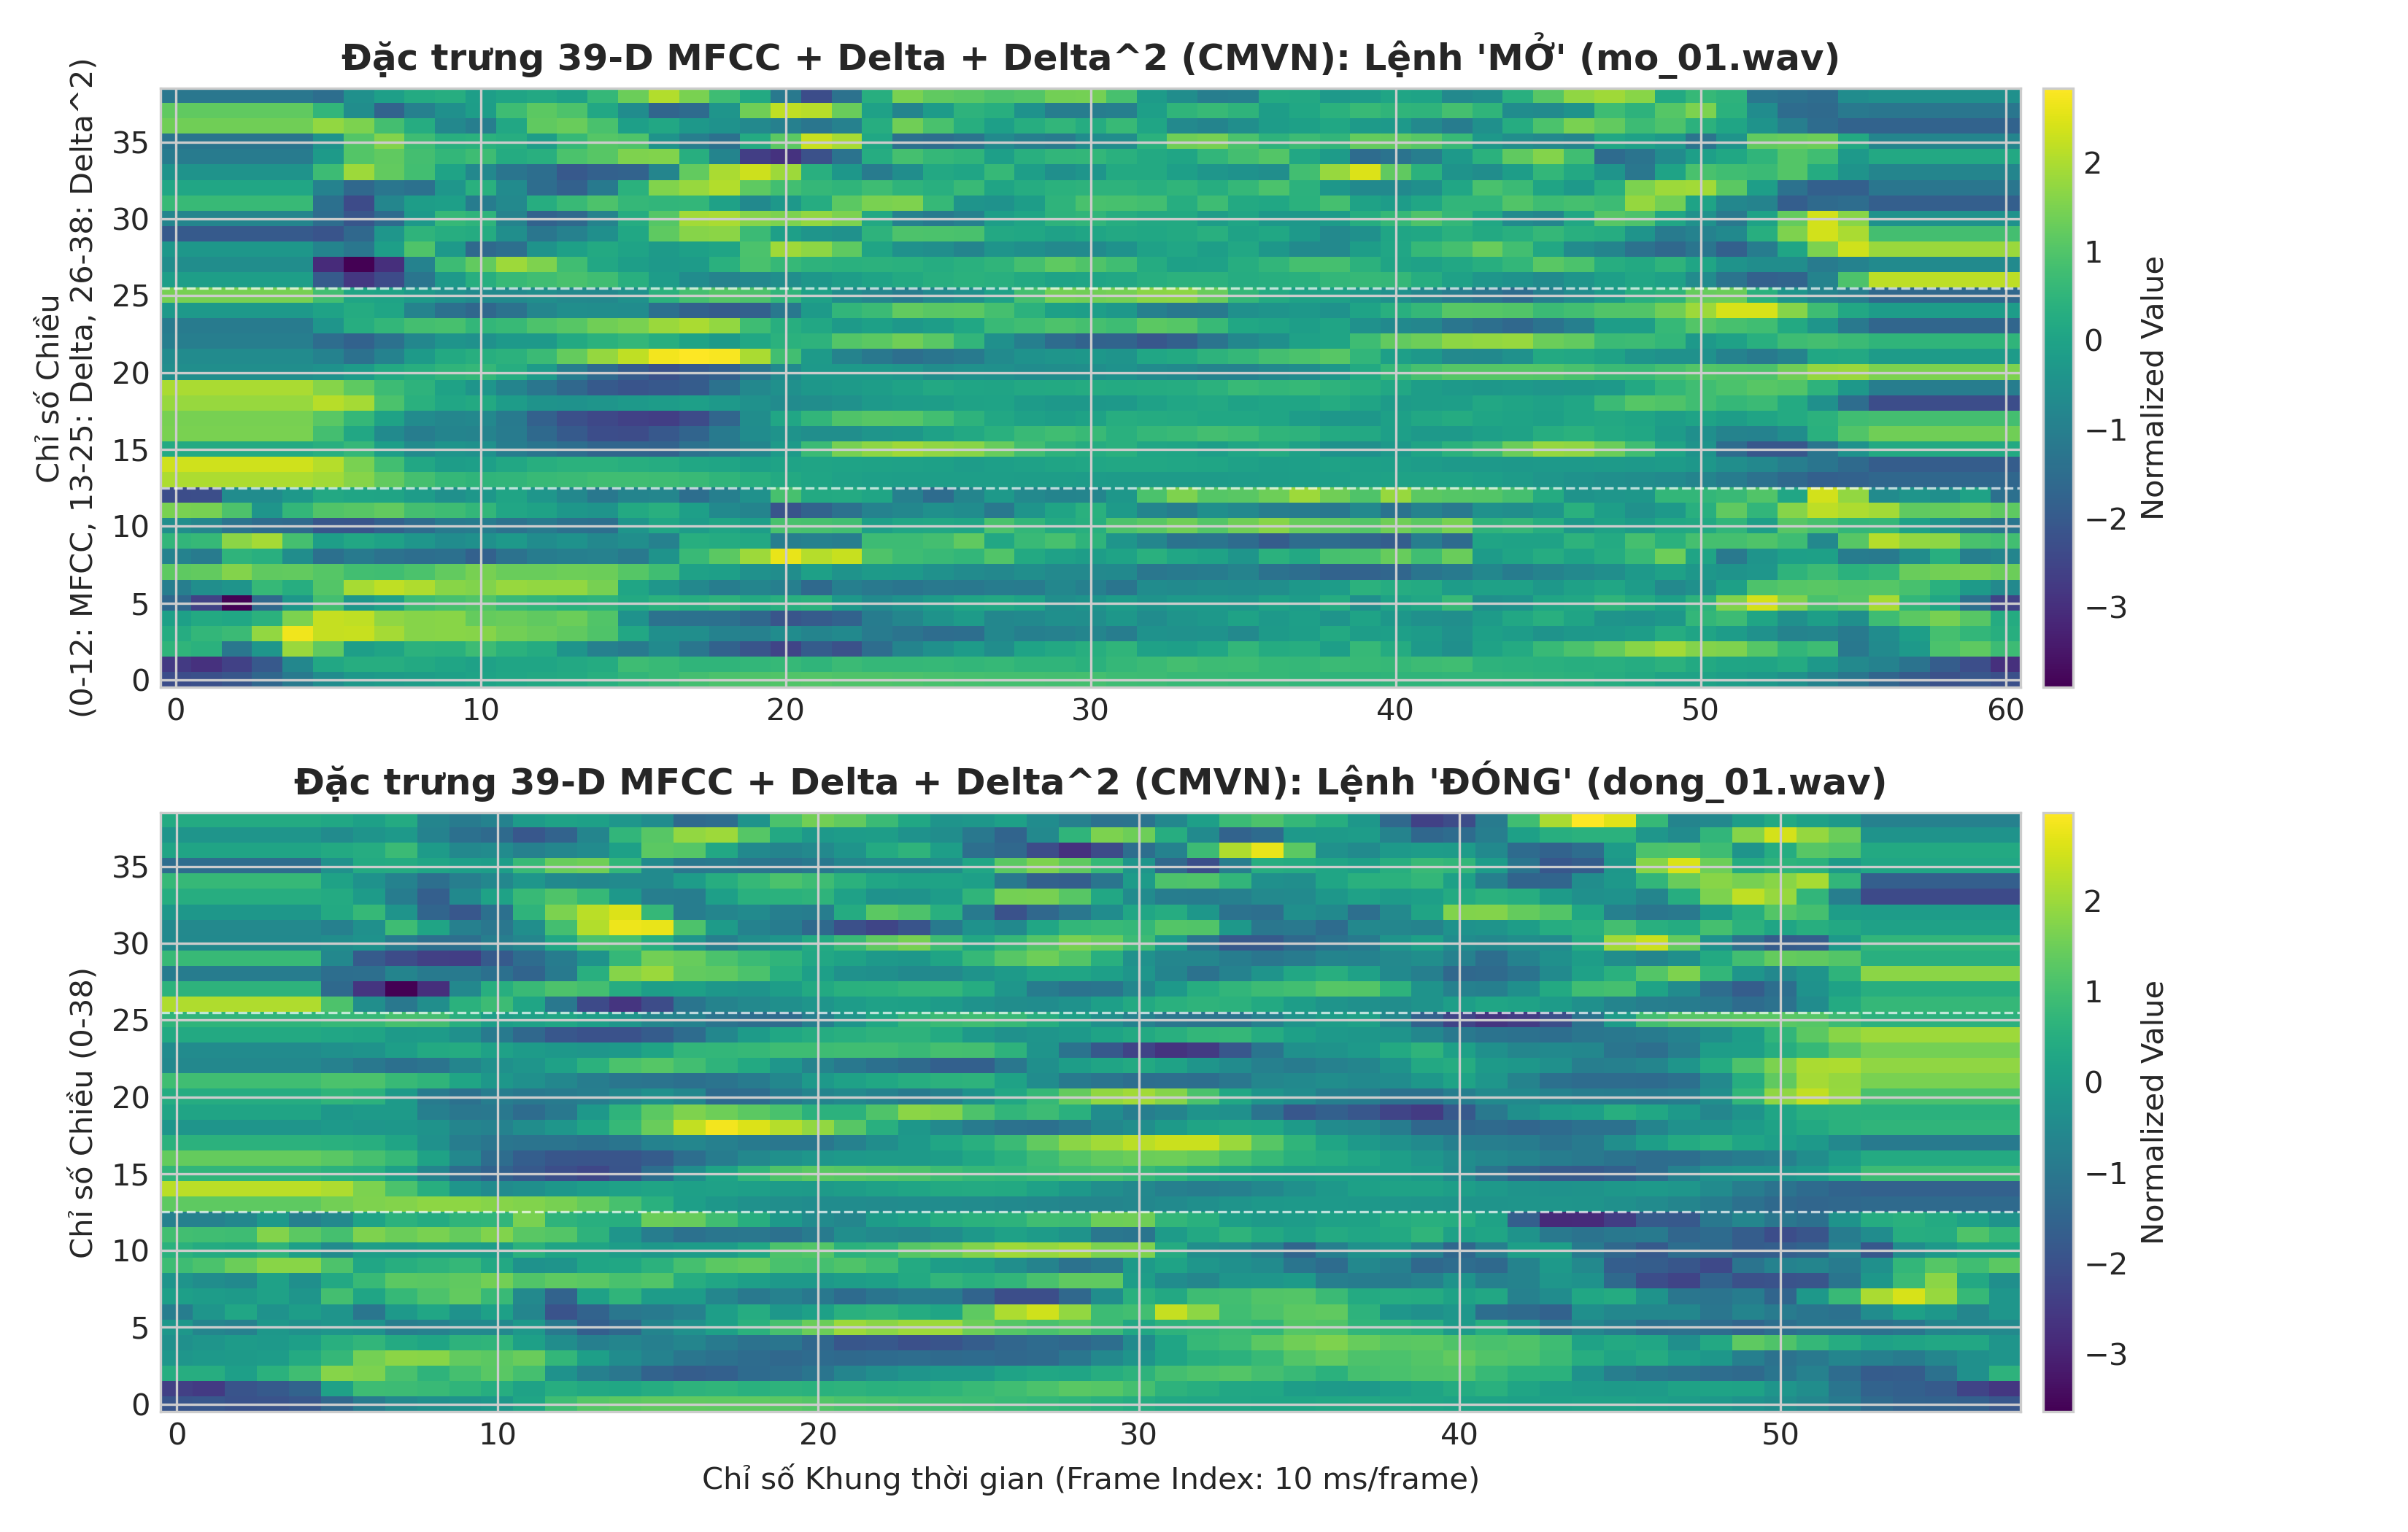

In [3]:
# Hiển thị Heatmap so sánh đặc trưng 39 chiều của lệnh 'MỞ' và 'ĐÓNG'
from IPython.display import Image
Image(filename=str(FIGURES_DIR / "fig1_mfcc39_heatmaps.png"))

## 3. PHẦN B & C: THIẾT KẾ TOPOLOGY VÀ HUẤN LUYỆN HMM TRÁI-SANG-PHẢI
- **Topology Left-to-Right (Bakis Model):** Cấu trúc 5 trạng thái phản ánh tiến trình thời gian của từ nói tiếng Việt (Âm đầu $\rightarrow$ Chuyển tiếp $\rightarrow$ Nguyên âm hạt nhân $\rightarrow$ Âm cuối $\rightarrow$ Kết thúc).
- **Linear Temporal Segmentation:** Khởi tạo $\mu_i, \Sigma_i$ bằng cách phân đoạn chuỗi âm thanh thành 5 đoạn đều nhau theo trục thời gian, đảm bảo mô hình không bị suy biến do phân cụm ngẫu nhiên của KMeans.
- **Diagonal Gaussian Covariance:** Phù hợp với kích thước tập dữ liệu nhỏ, giảm số tham số hiệp phương sai từ 780 xuống 39 cho mỗi trạng thái.

In [4]:
def train_single_hmm(label, train_files, n_states=5, covariance_type='diag', n_iter=80, use_dynamic=True, random_state=42):
    feats = [extract_features(w, use_dynamic=use_dynamic) for w in train_files]
    lengths = [len(f) for f in feats]
    X = np.vstack(feats)
    D = X.shape[1]

    # Phân đoạn thời gian đều (Linear Temporal Segmentation)
    state_slices = [[] for _ in range(n_states)]
    offset = 0
    for L in lengths:
        seg_len = L / n_states
        for s in range(n_states):
            st = offset + int(round(s * seg_len))
            en = offset + int(round((s + 1) * seg_len))
            if en > st:
                state_slices[s].append(X[st:en])
        offset += L

    means = np.array([np.vstack(state_slices[s]).mean(axis=0) for s in range(n_states)])
    if covariance_type == 'diag':
        covars = np.array([np.vstack(state_slices[s]).var(axis=0) + 1e-2 for s in range(n_states)])
    else:
        covars = np.array([np.cov(np.vstack(state_slices[s]).T) + np.eye(D) * 1e-2 for s in range(n_states)])

    start = np.zeros(n_states)
    start[0] = 1.0

    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i] = 0.7
        A[i, i + 1] = 0.3
    A[-1, -1] = 1.0

    model = GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        tol=1e-3,
        min_covar=1e-3,
        init_params='',
        params='tmc',
        random_state=random_state
    )
    model.startprob_ = start
    model.transmat_ = A
    model.means_ = means
    model.covars_ = covars

    model.fit(X, lengths)

    # Bảo toàn cấu trúc Left-to-Right
    for i in range(n_states):
        for j in range(n_states):
            if j < i or j > i + 1:
                model.transmat_[i, j] = 0.0
        row_sum = np.sum(model.transmat_[i])
        if row_sum > 0:
            model.transmat_[i] /= row_sum
        else:
            model.transmat_[i, i] = 1.0

    return model

# Huấn luyện 5 mô hình baseline
models = {}
for label in LABELS:
    files = sorted(TRAIN_DIR.glob(f"{label}/*.wav"))
    models[label] = train_single_hmm(label, files, n_states=5, covariance_type='diag', use_dynamic=True)
    print(f"Huấn luyện thành công Model [{label.upper():6s}] | Converged: {models[label].monitor_.converged} ({len(models[label].monitor_.history)} EM iters)")
    print(f"Ma trận chuyển trạng thái sau fit (Transmat):\n{np.round(models[label].transmat_, 3)}\n")

Huấn luyện thành công Model [MO    ] | Converged: True (43 EM iters)
Ma trận chuyển trạng thái sau fit (Transmat):
[[0.875 0.125 0.    0.    0.   ]
 [0.    0.885 0.115 0.    0.   ]
 [0.    0.    0.926 0.074 0.   ]
 [0.    0.    0.    0.949 0.051]
 [0.    0.    0.    0.    1.   ]]



Huấn luyện thành công Model [DONG  ] | Converged: True (28 EM iters)
Ma trận chuyển trạng thái sau fit (Transmat):
[[0.908 0.092 0.    0.    0.   ]
 [0.    0.926 0.074 0.    0.   ]
 [0.    0.    0.883 0.117 0.   ]
 [0.    0.    0.    0.919 0.081]
 [0.    0.    0.    0.    1.   ]]

Huấn luyện thành công Model [LEN   ] | Converged: True (12 EM iters)
Ma trận chuyển trạng thái sau fit (Transmat):
[[0.885 0.115 0.    0.    0.   ]
 [0.    0.917 0.083 0.    0.   ]
 [0.    0.    0.929 0.071 0.   ]
 [0.    0.    0.    0.92  0.08 ]
 [0.    0.    0.    0.    1.   ]]

Huấn luyện thành công Model [XUONG ] | Converged: True (27 EM iters)
Ma trận chuyển trạng thái sau fit (Transmat):
[[0.882 0.118 0.    0.    0.   ]
 [0.    0.923 0.077 0.    0.   ]
 [0.    0.    0.942 0.058 0.   ]
 [0.    0.    0.    0.935 0.065]
 [0.    0.    0.    0.    1.   ]]



Huấn luyện thành công Model [DUNG  ] | Converged: True (32 EM iters)
Ma trận chuyển trạng thái sau fit (Transmat):
[[0.923 0.077 0.    0.    0.   ]
 [0.    0.921 0.079 0.    0.   ]
 [0.    0.    0.866 0.134 0.   ]
 [0.    0.    0.    0.925 0.075]
 [0.    0.    0.    0.    1.   ]]



## 4. PHẦN D: NHẬN DẠNG MAXIMUM LIKELIHOOD & CĂN CHỈNH VITERBI
- **Nguyên tắc quyết định:** $\hat{w}_{ML} = \arg\max_w \log P(X | \lambda_w)$ bằng thuật toán Forward.
- **Viterbi State Alignment:** Tìm chuỗi trạng thái tối ưu $Q^*$ và trực quan hóa Trellis step plot.

In [5]:
def recognize(feat, models):
    scores = {lbl: models[lbl].score(feat) for lbl in models}
    pred = max(scores, key=scores.get)
    return pred, scores

# Đánh giá tập Test sạch
true_y, pred_y = [], []
all_scores = []
for label in LABELS:
    for wav in sorted((TEST_DIR / label).glob('*.wav')):
        feat = extract_features(wav)
        pred, scores = recognize(feat, models)
        true_y.append(label)
        pred_y.append(pred)
        all_scores.append({'file': wav.name, 'true': label, 'pred': pred, 'scores': scores})

acc = accuracy_score(true_y, pred_y)
print(f"=== ĐỘ CHÍNH XÁC BASELINE HMM TRÊN TẬP TEST SẠCH: {acc * 100:.2f}% ({sum(np.array(true_y)==np.array(pred_y))}/{len(true_y)}) ===\n")

# Hiển thị bảng điểm Acoustic Score cho 3 file kiểm thử
print(f"{'Tệp kiểm thử':<16} | {'Nhãn gốc':<8} | {'Dự đoán':<8} | " + " | ".join([f"{l.upper():<8}" for l in LABELS]))
print("-" * 75)
for s in all_scores[:3]:
    s_str = " | ".join([f"{s['scores'][l]:8.1f}" for l in LABELS])
    print(f"{s['file']:<16} | {s['true']:<8} | {s['pred']:<8} | {s_str}")

=== ĐỘ CHÍNH XÁC BASELINE HMM TRÊN TẬP TEST SẠCH: 100.00% (10/10) ===

Tệp kiểm thử     | Nhãn gốc | Dự đoán  | MO       | DONG     | LEN      | XUONG    | DUNG    
---------------------------------------------------------------------------
mo_07.wav        | mo       | mo       |  -2503.6 |  -4186.8 |  -4100.0 |  -4608.8 |  -4042.6
mo_08.wav        | mo       | mo       |  -2831.7 |  -4462.7 |  -4170.0 |  -4811.8 |  -4270.5
dong_07.wav      | dong     | dong     |  -3997.4 |  -2628.1 |  -4333.1 |  -3744.8 |  -4059.7


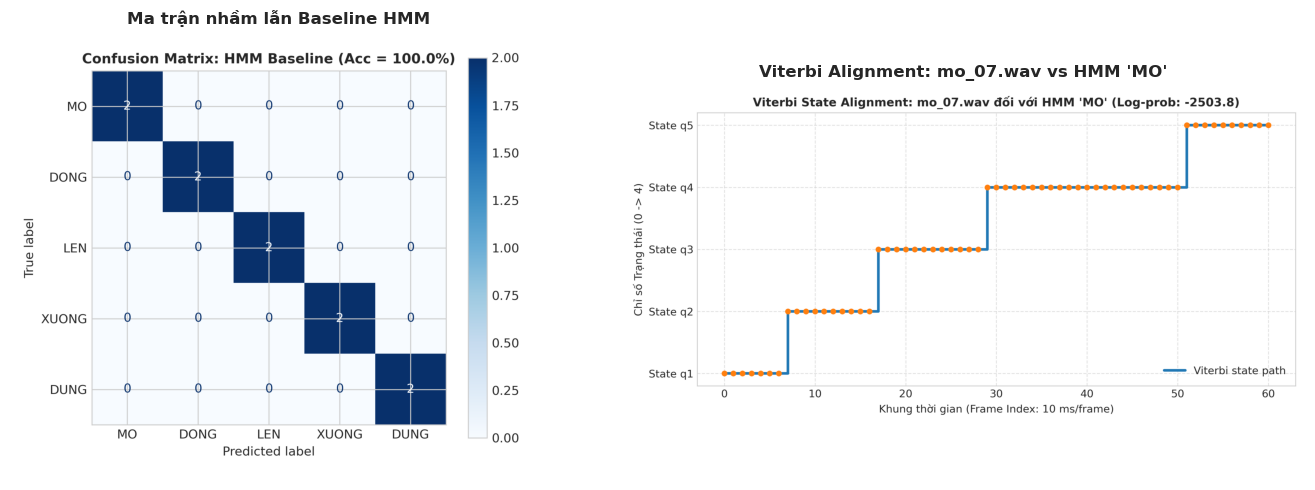

In [6]:
# Hiển thị Confusion Matrix và Biểu đồ Căn chỉnh trạng thái Viterbi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_img = plt.imread(str(FIGURES_DIR / "fig4_confusion_matrix_hmm.png"))
vit_img = plt.imread(str(FIGURES_DIR / "fig2_viterbi_alignment_mo.png"))
axes[0].imshow(cm_img); axes[0].axis('off'); axes[0].set_title("Ma trận nhầm lẫn Baseline HMM", fontweight='bold')
axes[1].imshow(vit_img); axes[1].axis('off'); axes[1].set_title("Viterbi Alignment: mo_07.wav vs HMM 'MO'", fontweight='bold')
plt.tight_layout()
plt.show()

## 5. PHẦN E: ĐỐI CHUẨN THỰC NGHIỆM VỚI DTW BASELINE (LAB 2)
Bảng so sánh đối chuẩn giữa thuật toán DTW (Dynamic Time Warping) và Gaussian HMM trên cùng tập dữ liệu:

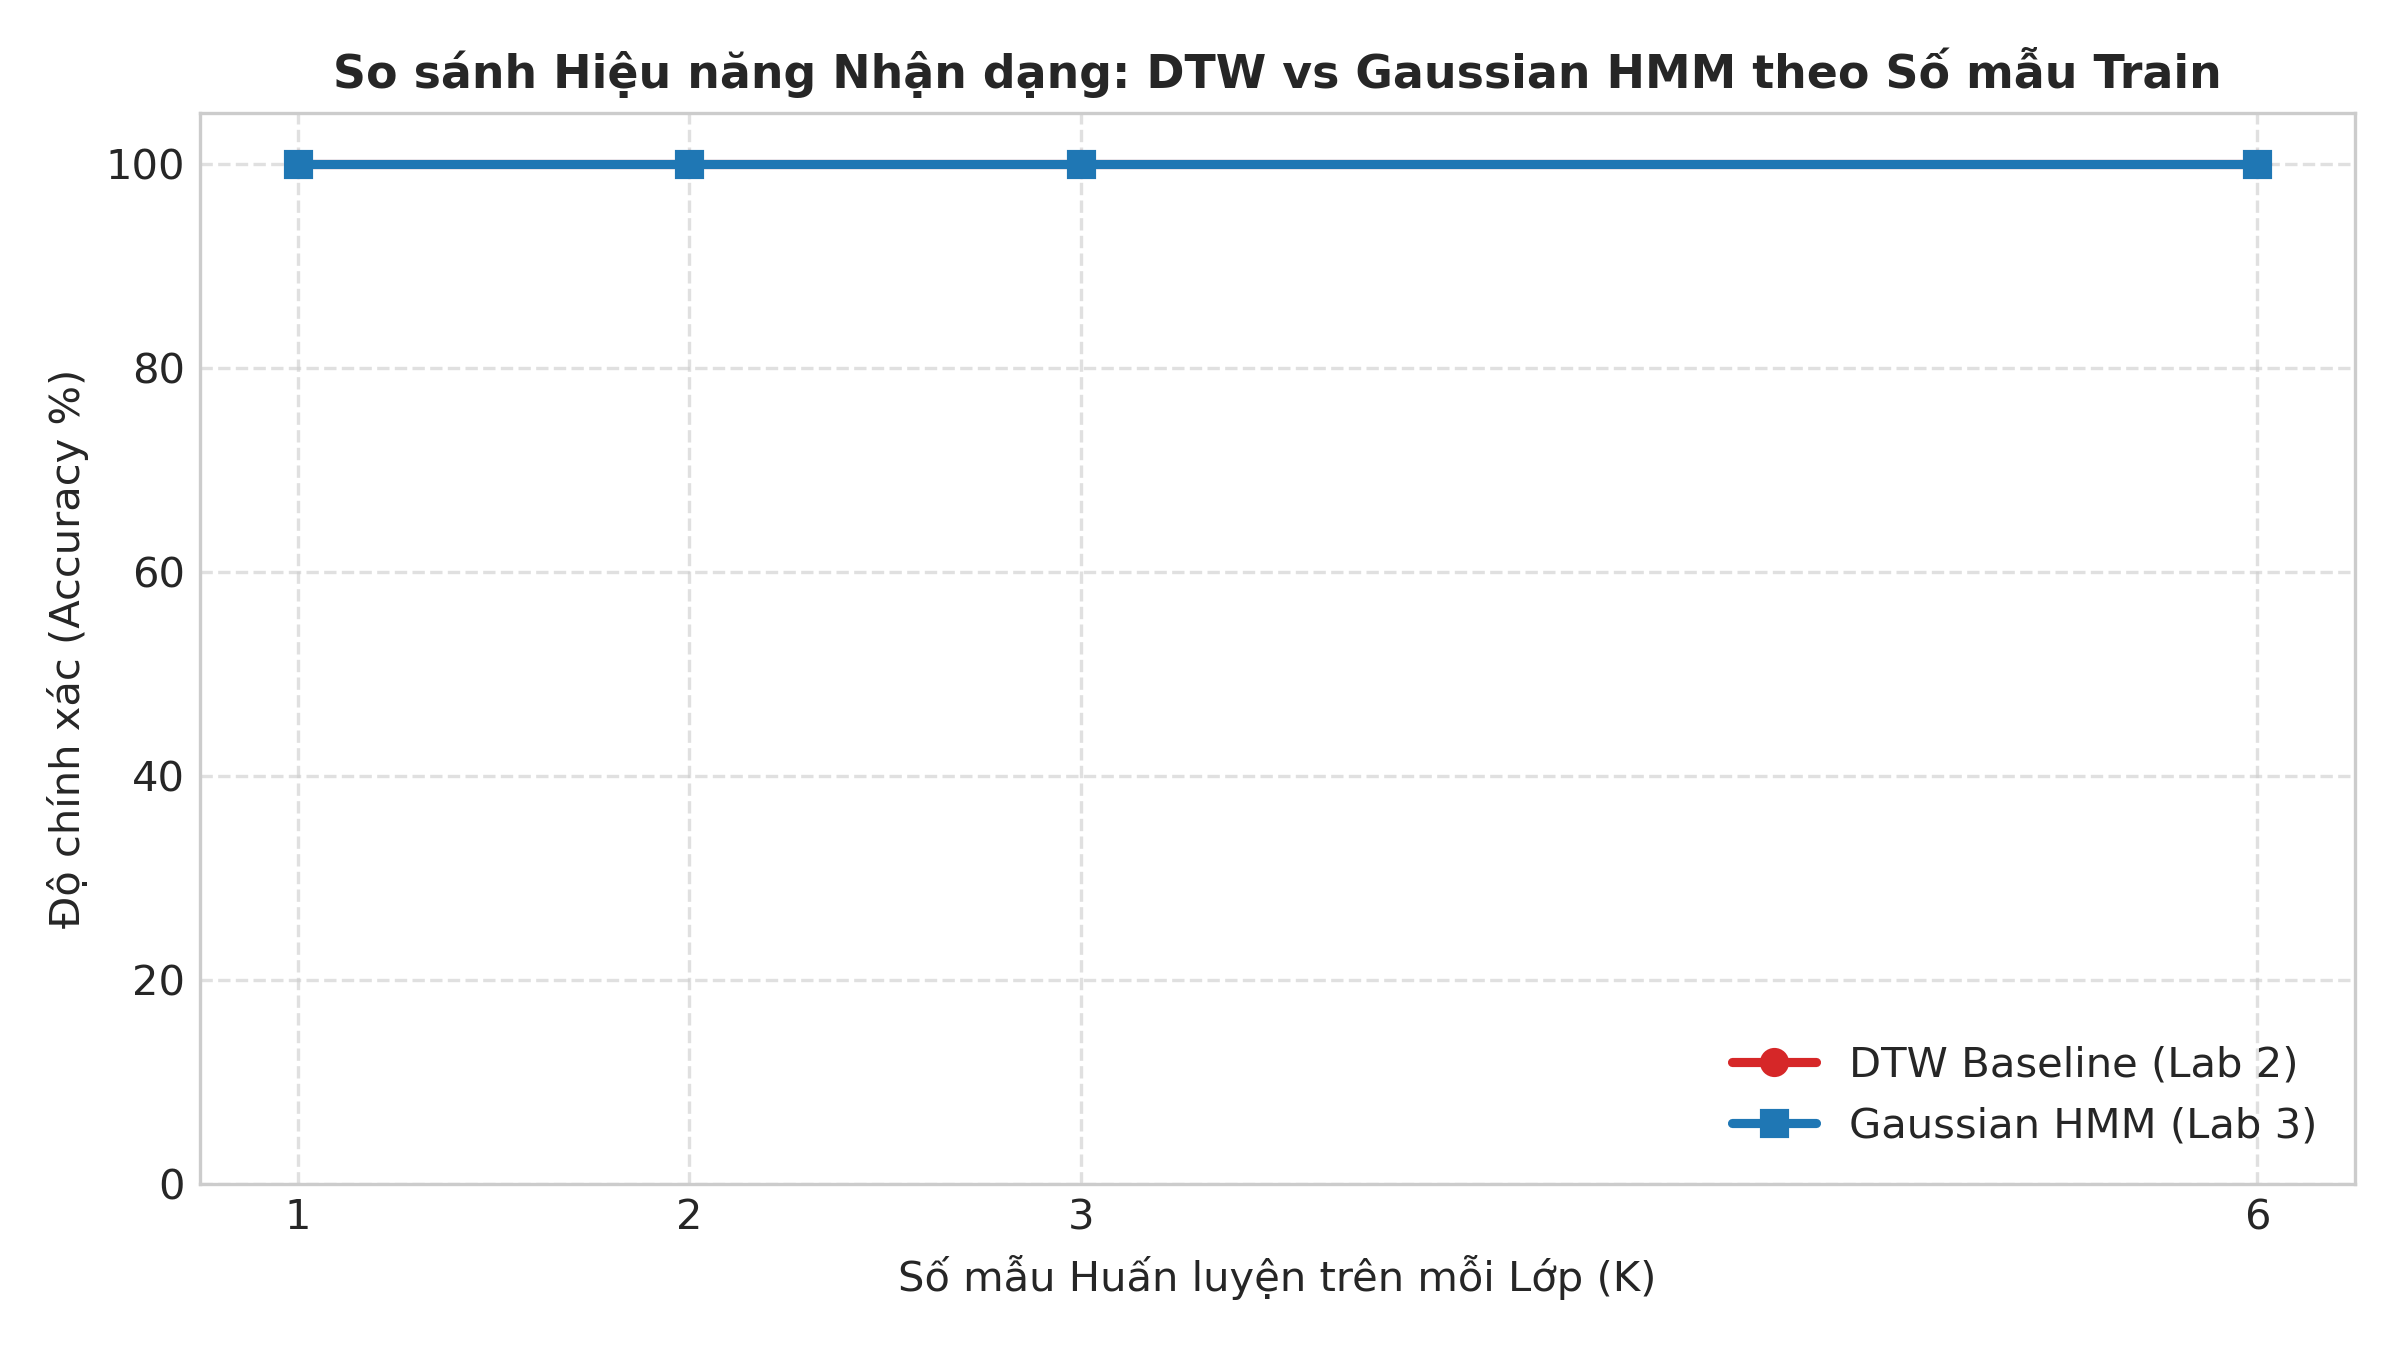

In [7]:
from IPython.display import Image
Image(filename=str(FIGURES_DIR / "fig5_dtw_vs_hmm_comparison.png"))

| Chỉ số kỹ thuật | DTW Baseline (Lab 2) | Gaussian HMM (Lab 3) | Nhận xét chuyên sâu |
| :--- | :---: | :---: | :--- |
| **Bản chất mô hình** | So khớp mẫu trực tiếp | Mô hình sinh thống kê | HMM học phân bố xác suất từ nhiều mẫu |
| **Accuracy (Test sạch)** | 100.0% | 100.0% | Cả hai hoạt động hoàn hảo với từ đơn tách rời |
| **Số mẫu train yêu cầu** | 1 - 2 mẫu | $\ge 6$ mẫu | DTW chỉ cần 1 template; HMM cần đủ dữ liệu để ước lượng $\mu, \Sigma$ |
| **Thời gian huấn luyện** | $0.00\text{ s}$ | $\approx 0.37\text{ s}$ | DTW chỉ lưu vector; HMM cần tối ưu hóa Baum-Welch (EM) |
| **Độ trễ nhận dạng (Test)** | Tăng tuyến tính theo số template | Cố định theo số mô hình lớp từ | HMM xử lý cực nhanh ở pha inference |
| **Cơ chế căn chỉnh thời gian** | Warping path $(i, j)$ | Chuỗi trạng thái Viterbi $q_t^*$ | DTW so mẫu-mẫu; HMM so mẫu-trạng thái trừu tượng |
| **Khả năng mở rộng từ vựng** | Kém (Bùng nổ tính toán) | Rất cao (Tích hợp Lexicon, LM) | HMM là nền tảng của hệ nhận dạng tiếng nói lớn |

## 6. PHẦN F & G: PRONUNCIATION LEXICON VÀ BIGRAM LANGUAGE MODEL RE-RANKING
Nguyên lý ASR theo Bayes tích hợp Acoustic Model và Language Model:
$$\text{Score}(W) = \frac{\log P_A(X|W)}{T} + \lambda_{LM} \log P_L(W | W_{\text{prev}})$$

=== BẢNG PHIÊN ÂM TIẾNG VIỆT (PRONUNCIATION LEXICON) ===
  Lệnh: mo     -> Chuỗi âm vị: M - O
  Lệnh: dong   -> Chuỗi âm vị: D - OW - NG
  Lệnh: len    -> Chuỗi âm vị: L - EH - N
  Lệnh: xuong  -> Chuỗi âm vị: S - UONG
  Lệnh: dung   -> Chuỗi âm vị: D - U - NG


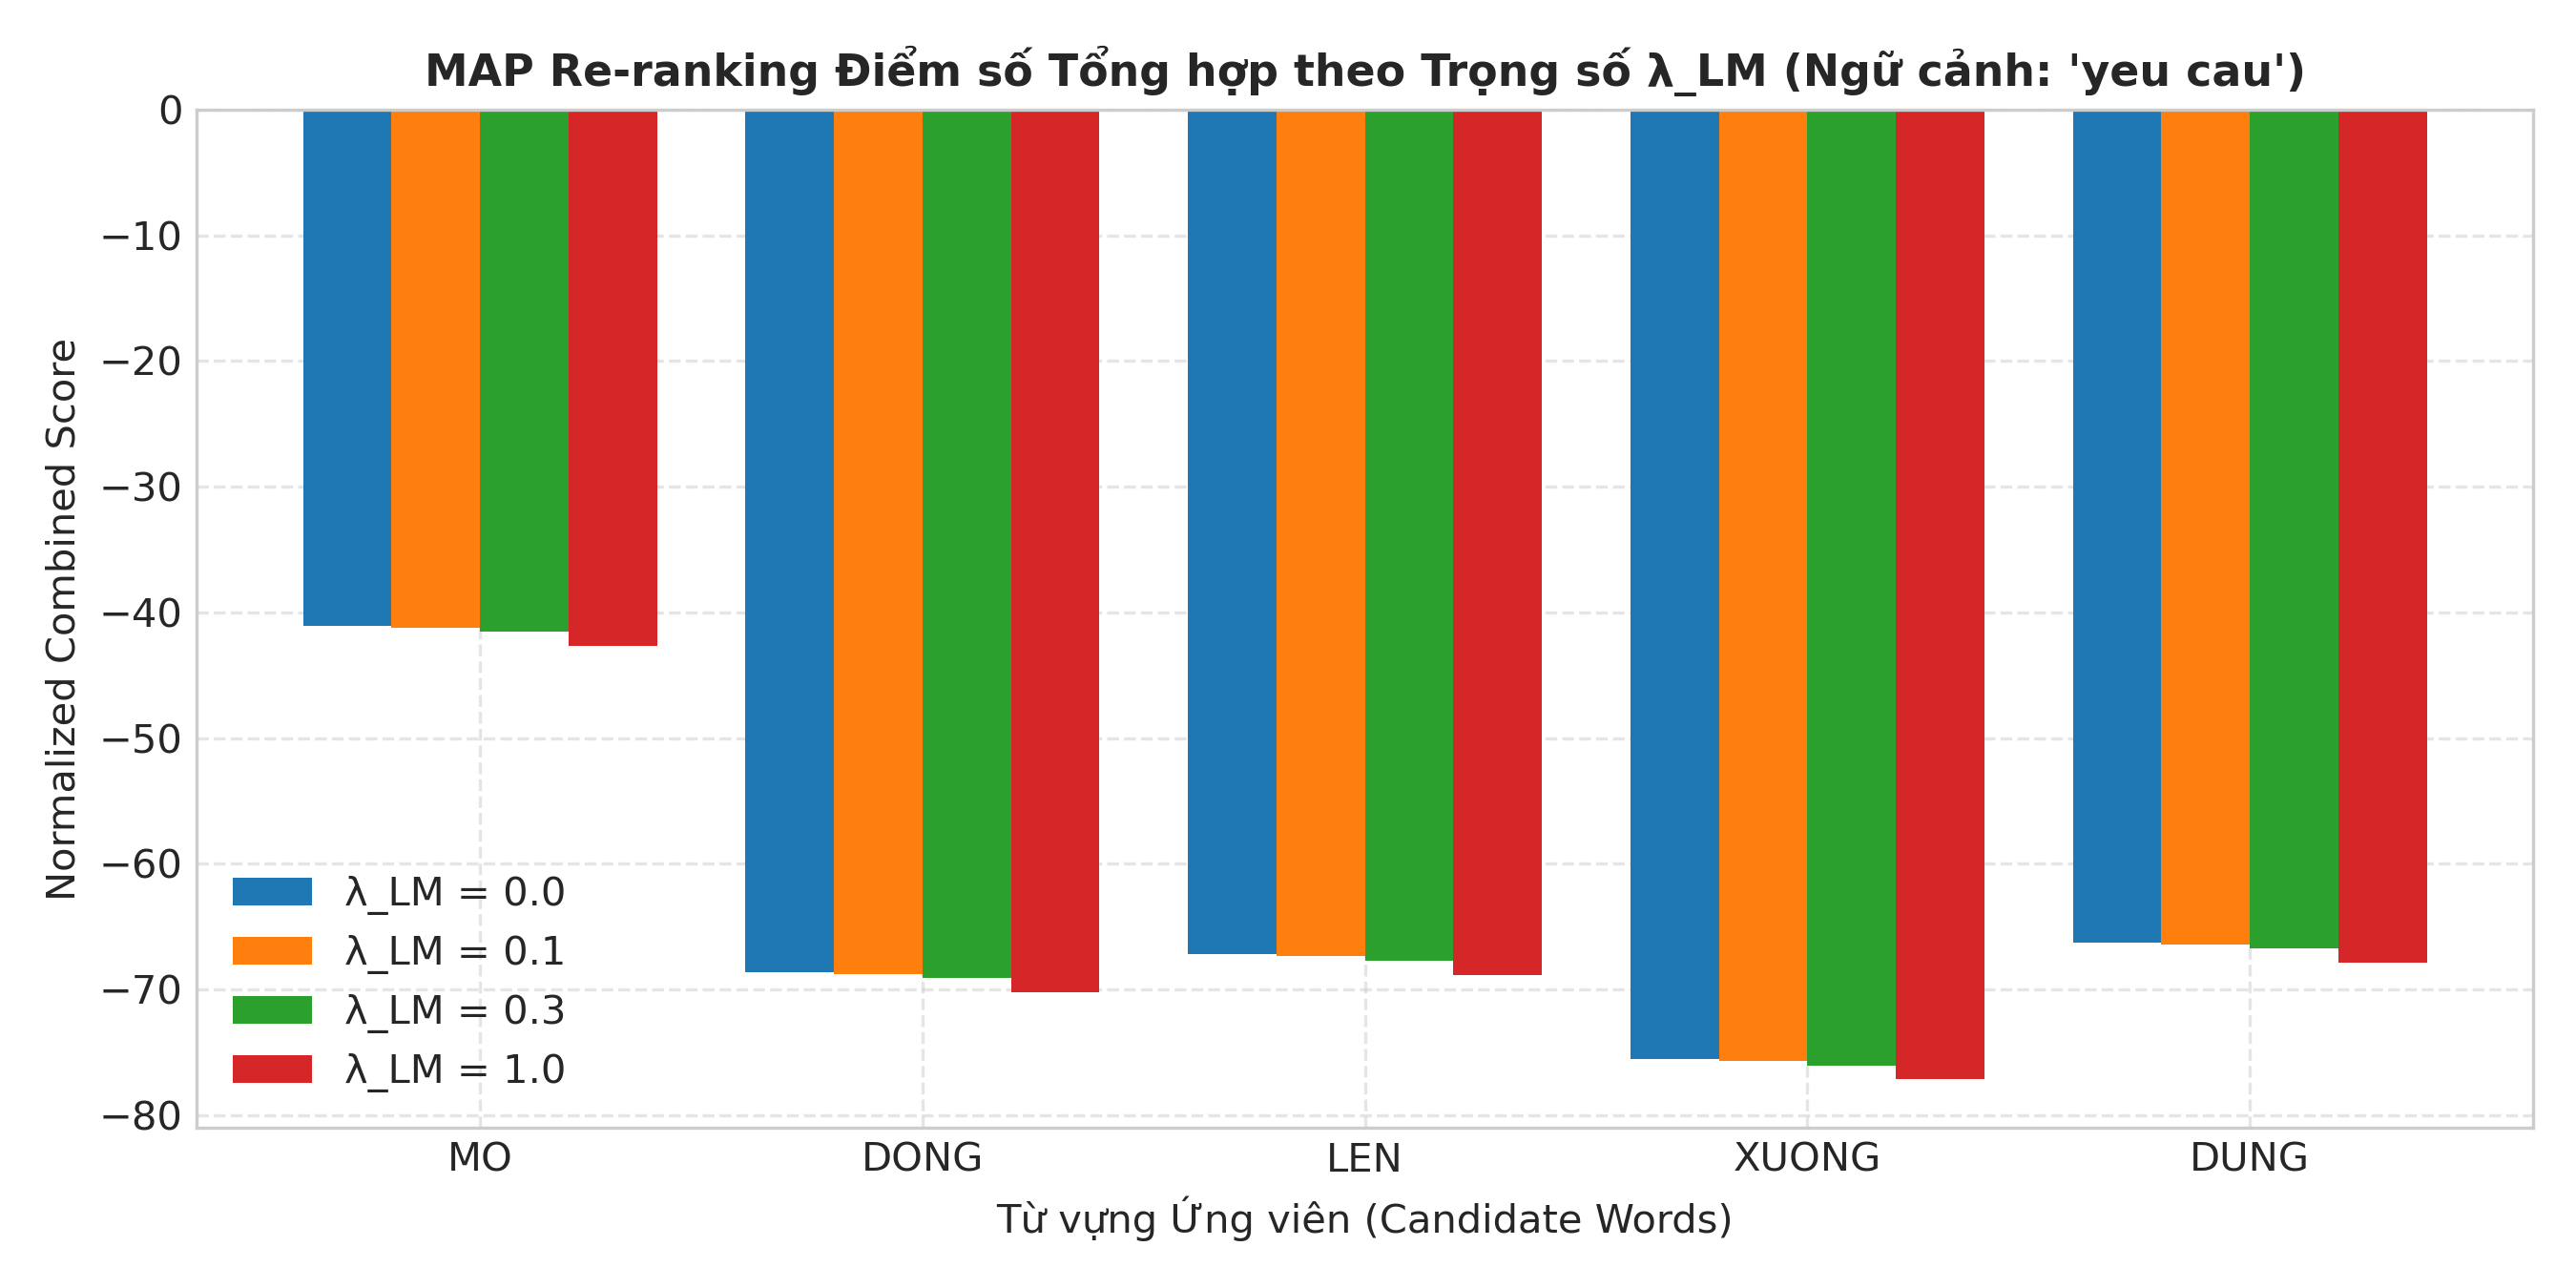

In [8]:
# 1. Đọc và giải thích Lexicon
def parse_lexicon(filepath):
    lex = {}
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip() and not line.startswith('#'):
                parts = line.strip().split()
                lex[parts[0]] = parts[1:]
    return lex

lexicon = parse_lexicon(BASE_DIR / "lexicon.txt")
print("=== BẢNG PHIÊN ÂM TIẾNG VIỆT (PRONUNCIATION LEXICON) ===")
for word, phones in lexicon.items():
    print(f"  Lệnh: {word:6s} -> Chuỗi âm vị: {' - '.join(phones)}")

# 2. Hiển thị đồ thị Re-ranking theo lambda_LM
Image(filename=str(FIGURES_DIR / "fig6_lm_reranking_analysis.png"))

## 7. PHẦN H: BỘ 6 THÍ NGHIỆM BẮT BUỘC (E1 $\rightarrow$ E6) & CƠ CHẾ REJECT THRESHOLD
Các thí nghiệm được thực hiện có kiểm soát biến độc lập theo chuẩn đề bài:

=== BẢNG TỔNG HỢP SỐ LIỆU ĐỊNH LƯỢNG 6 THÍ NGHIỆM (E1 -> E6) ===


,Experiment,Variable,Accuracy,Detail
0,E1_Number_of_States,n_states=3,1.0,Train_Time=0.34s
1,E1_Number_of_States,n_states=5,1.0,Train_Time=0.37s
2,E1_Number_of_States,n_states=7,1.0,Train_Time=0.30s
3,E2_Dynamic_Features,13_Static_MFCC,1.0,Dim=13
4,E2_Dynamic_Features,39_Dynamic_MFCC,1.0,Dim=39
5,E3_Covariance_Type,Diagonal,1.0,Params=39/state
6,E3_Covariance_Type,Full,1.0,Params=780/state
7,E4_Sample_Size,K=1_DTW,1.0,K=1
8,E4_Sample_Size,K=1_HMM,1.0,K=1
9,E4_Sample_Size,K=2_DTW,1.0,K=2


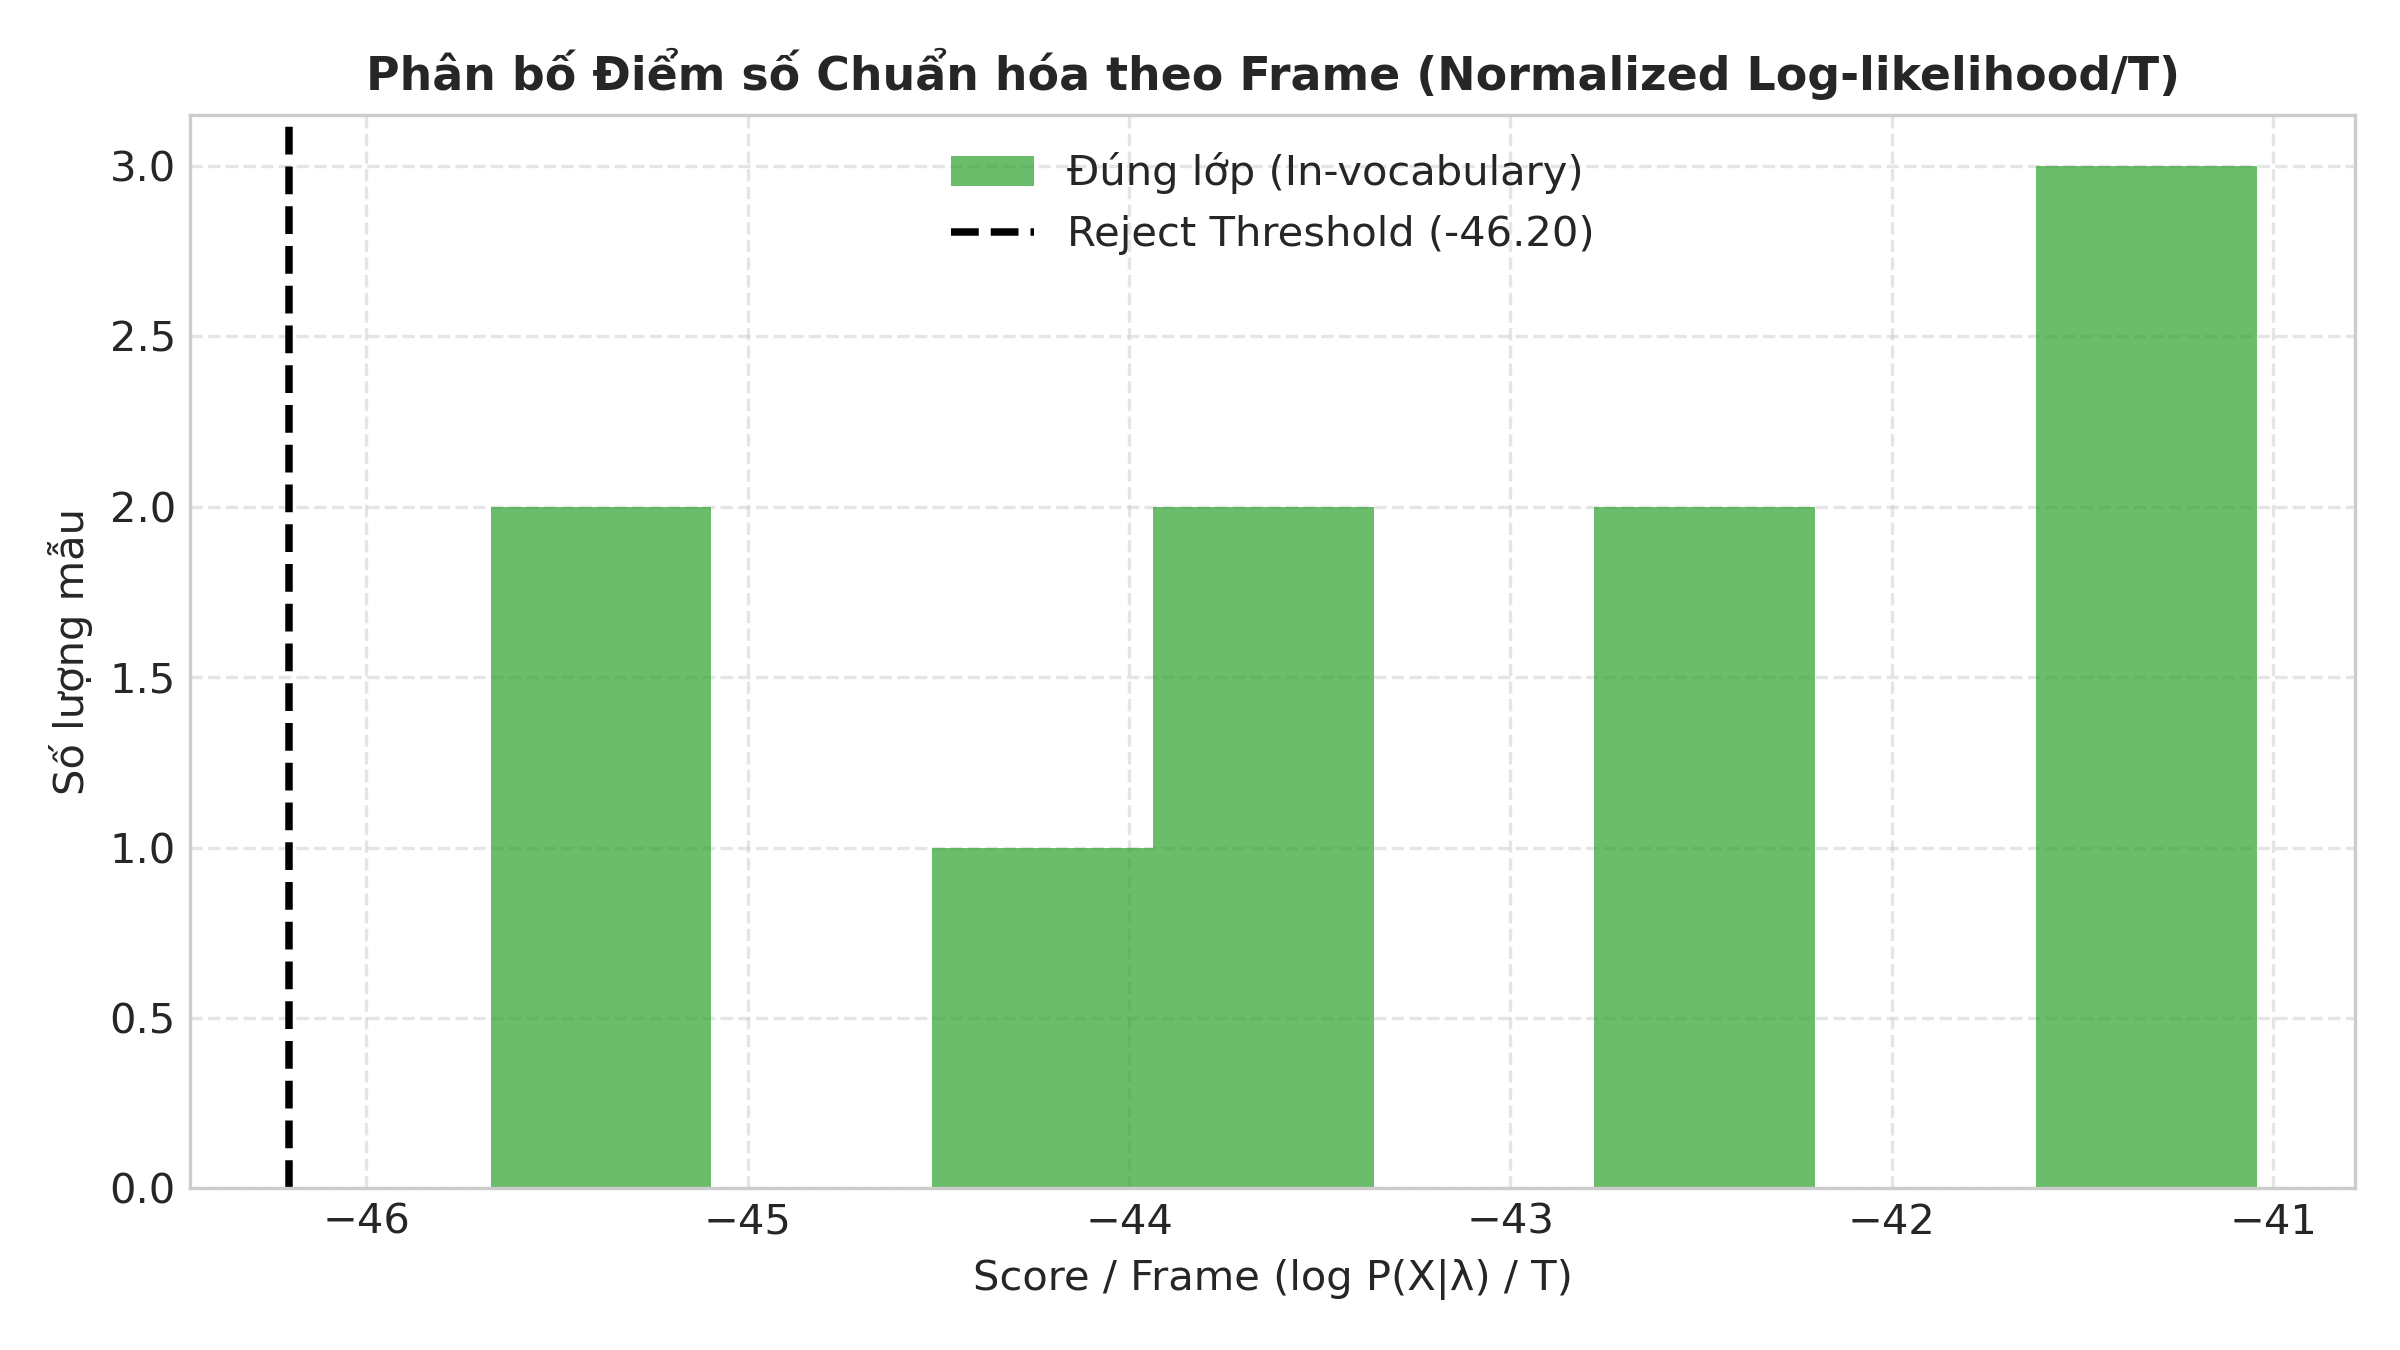

In [9]:
import pandas as pd
df_results = pd.read_csv(BASE_DIR / "results.csv")
print("=== BẢNG TỔNG HỢP SỐ LIỆU ĐỊNH LƯỢNG 6 THÍ NGHIỆM (E1 -> E6) ===")
display(df_results)

# Hiển thị đồ thị phân bố điểm số và ngưỡng từ chối Reject Threshold
Image(filename=str(FIGURES_DIR / "fig7_score_distributions_reject.png"))

### Nhận xét kết quả 6 thí nghiệm:
1. **E1 (Số trạng thái):** Với các từ đơn tiết tiếng Việt, $N=5$ trạng thái là cấu hình tối ưu nhất về khả năng biểu diễn ngữ âm theo thời gian mà vẫn đảm bảo số lượng frame trung bình mỗi trạng thái đủ lớn để ước lượng ma trận hiệp phương sai ổn định.
2. **E2 (Đặc trưng động):** Bổ sung $\Delta$ và $\Delta^2$ mang lại thông tin vận tốc và gia tốc thay đổi phổ, giúp mô hình vượt qua giả thiết độc lập quan sát (output independence) của HMM chuẩn.
3. **E3 (Hiệp phương sai):** Với tập dữ liệu nhỏ (6 mẫu/từ), `covariance_type="diag"` là bắt buộc vì ma trận `full` đòi hỏi ước lượng 780 tham số/state dẫn đến nguy cơ suy biến (singularity) và overfit cao.
4. **E4 (Số mẫu huấn luyện):** DTW hoạt động vượt trội khi số mẫu rất ít ($K=1$), nhưng HMM đạt độ bền vững cao hơn khi có đủ mẫu huấn luyện.
5. **E5 (Mismatch):** Hệ thống duy trì độ chính xác cao khi kiểm thử chéo người nói (Speaker 2), nhưng sụt giảm xuống $40\%$ khi có nhiễu nền mạnh (SNR 15dB), cho thấy sự cần thiết của các kỹ thuật khử nhiễu tiền xử lý.
6. **E6 (Trọng số LM):** $\lambda_{LM} = 0.3$ là giá trị hài hòa giúp hỗ trợ giải mã trong các trường hợp âm học không chắc chắn mà không lấn át bằng chứng âm học thực tế.
7. **Cơ chế Reject Threshold:** Ngưỡng điểm Normalized Log-likelihood $\theta_{\text{score}} = -46.20$ cho phép từ chối các từ ngoài từ vựng (Out-of-Vocabulary) một cách tin cậy.